# 03b — Follow-ups to Phase 3 (validation only)

1. **Within cell type x sample.** With a random split, cells of the same sample are in both training and
   validation. If ridge used sample/site signatures in RNA to predict the site-dependent protein
   background, its within-type correlation would drop once we also hold the sample fixed. This is
   compared with the own-gene result from Phase 2 (0.07 -> 0.06).
2. **Within-type Pearson by number of PCA components (50 ... 2,000).** Tests the hypothesis "PCA loses
   within-type information".

The features are rebuilt exactly as in notebook 03 (train-only HVG/PCA, same split). Notebook 03's
validation predictions are reproduced first as a check. Test cells are never loaded.

In [1]:
import os, sys, time, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from citeseq.paths import RESULTS_DIR, FIGURES_DIR, PROCESSED_DIR
from citeseq.data_prep import load_train_val
from citeseq.baselines import OwnGeneLinear, RidgePath, HVGPCAFeatures, CellTypeMean
from citeseq.correlation import pearson_columns
from citeseq.metrics import evaluate
from citeseq import plotting as P

SUBSET = int(os.environ.get("CITESEQ_SUBSET", 0)) or None
cfg = json.loads((RESULTS_DIR / "phase3_frozen_configs.json").read_text())
MIN_CELLS = 50
ALPHAS = cfg["grids"]["3a_alphas_initial"]
PCS = cfg["grids"]["3a_n_pcs"]
P.set_style()
pd.set_option("display.float_format", "{:.3f}".format)
OUT_FIG = FIGURES_DIR if SUBSET is None else PROCESSED_DIR / "test_figures"
OUT_FIG.mkdir(parents=True, exist_ok=True)

d = load_train_val(RESULTS_DIR / "splits/random_split.csv.gz", subset=SUBSET)
proteins, pmap = d["proteins"], d["pmap"]
primary = pmap.index[pmap["analysis_set"] == "primary"].tolist()
ct_va = d["obs_va"]["cell_type"].astype(str).to_numpy()
ts_va = (d["obs_va"]["cell_type"].astype(str) + " | " + d["obs_va"]["batch"].astype(str)).to_numpy()
print("train", d["X_tr"].shape[0], "| val", d["X_va"].shape[0], "| test cells not loaded:", d["n_test"])

train 63182 | val 13539 | test cells not loaded: 13540


In [2]:
t0 = time.time()
feats = HVGPCAFeatures(n_top_genes=cfg["features"]["hvg"], max_pcs=None, seed=cfg["seed"]).fit(
    d["X_tr"], d["obs_tr"], d["gene_names"])
Z_tr, Z_va = feats.transform_pca(d["X_tr"], 2000), feats.transform_pca(d["X_va"], 2000)
H_tr, H_va = feats.transform_hvg(d["X_tr"]), feats.transform_hvg(d["X_va"])
Y_tr, Y_va = d["Y_tr"], d["Y_va"]
n3a, a3a, a3b = cfg["3a_ridge_pca"]["n_pcs"], cfg["3a_ridge_pca"]["alpha"], cfg["3b_ridge_hvg"]["alpha"]
pred = {
    "own gene": OwnGeneLinear().fit(d["R_tr"], Y_tr).predict(d["R_va"]),
    "cell-type mean (labels)": CellTypeMean().fit(Y_tr, d["obs_tr"]["cell_type"]).predict(ct_va),
    "ridge PCA (full rank)": RidgePath().fit(Z_tr[:, :n3a], Y_tr, [a3a]).predict(Z_va[:, :n3a], a3a),
    "ridge HVG": RidgePath().fit(H_tr, Y_tr, [a3b]).predict(H_va, a3b),
}
print(f"features + models in {time.time() - t0:.0f}s")
if SUBSET is None:
    saved = np.load(PROCESSED_DIR / "phase3_val_predictions.npz")
    for k_saved, k_now in [("3a_ridge_PCA", "ridge PCA (full rank)"), ("3b_ridge_HVG", "ridge HVG"), ("2_own_gene", "own gene")]:
        diff = np.nanmax(np.abs(saved[k_saved] - pred[k_now]))
        print(f"reproduces notebook 03 '{k_saved}': max |diff| = {diff:.2e}")

features + models in 23s
reproduces notebook 03 '3a_ridge_PCA': max |diff| = 2.38e-07
reproduces notebook 03 '3b_ridge_HVG': max |diff| = 2.38e-07
reproduces notebook 03 '2_own_gene': max |diff| = 2.38e-07


## 1. Within cell type vs. within cell type x sample (validation)

Groups need >= 50 validation cells. Values are medians over the 110 primary proteins of the
cell-weighted mean within-group Pearson.

In [3]:
rows = []
for m, p in pred.items():
    e_t = evaluate(Y_va, p, ct_va, proteins, MIN_CELLS).loc[primary]
    e_ts = evaluate(Y_va, p, ts_va, proteins, MIN_CELLS).loc[primary]
    rows.append({"model": m, "data": "validation (Phase 3 split)",
                 "within type": e_t["within_w"].median(), "within type x sample": e_ts["within_w"].median(),
                 "n groups (type / type x sample)": f"{int(e_t['n_types'].median())} / {int(e_ts['n_types'].median())}"})
p2 = pd.read_csv(RESULTS_DIR / "phase2_protein_rna_correlation.csv")
p2p = p2[p2["analysis_set"] == "primary"]
rows.insert(0, {"model": "own gene (Phase 2, correlation)", "data": "all cells",
                "within type": p2p["pearson_within_w"].median(), "within type x sample": p2p["pearson_within_type_sample_w"].median(),
                "n groups (type / type x sample)": "42 / 296"})
ts_table = pd.DataFrame(rows).set_index("model")
ts_table["change"] = ts_table["within type x sample"] - ts_table["within type"]
ts_table

/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/Users/ardaqas/aa/.venv/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


,data,within type,within type x sample,n groups (type / type x sample),change
model,,,,,
"own gene (Phase 2, correlation)",all cells,0.072,0.062,42 / 296,-0.011
own gene,validation (Phase 3 split),0.080,0.061,34 / 72,-0.019
cell-type mean (labels),validation (Phase 3 split),NaN,NaN,34 / 72,NaN
ridge PCA (full rank),validation (Phase 3 split),0.337,0.104,34 / 72,-0.233
ridge HVG,validation (Phase 3 split),0.333,0.101,34 / 72,-0.231


## 2. Within-type Pearson by number of PCA components (validation)

In [4]:
def sel_metric(p):
    return float(np.nanmean(pearson_columns(p, Y_va)))

curve = []
for n in PCS:
    rp = RidgePath().fit(Z_tr[:, :n], Y_tr, ALPHAS)
    scores = {a: sel_metric(rp.predict(Z_va[:, :n], a)) for a in ALPHAS}
    a_best = max(scores, key=scores.get)       # same rule as notebook 03, per n
    e = evaluate(Y_va, rp.predict(Z_va[:, :n], a_best), ct_va, proteins, MIN_CELLS).loc[primary]
    curve.append({"n_pcs": n, "alpha": a_best, "selection_metric": scores[a_best],
                  "pearson_all": e["pearson_all"].median(), "within_w": e["within_w"].median(),
                  "within_unw": e["within_unw"].median()})
e_h = evaluate(Y_va, pred["ridge HVG"], ct_va, proteins, MIN_CELLS).loc[primary]
curve = pd.DataFrame(curve)
curve

,n_pcs,alpha,selection_metric,pearson_all,within_w,within_unw
0,50,316.228,0.645,0.695,0.274,0.266
1,100,1000.000,0.655,0.704,0.290,0.285
2,200,1000.000,0.662,0.713,0.301,0.296
3,400,1000.000,0.668,0.717,0.311,0.308
4,800,3162.278,0.674,0.721,0.323,0.314
5,2000,1000.000,0.682,0.733,0.337,0.326


50 PCs reach 81% of the full-rank within-type r and 95% of the full-rank overall r


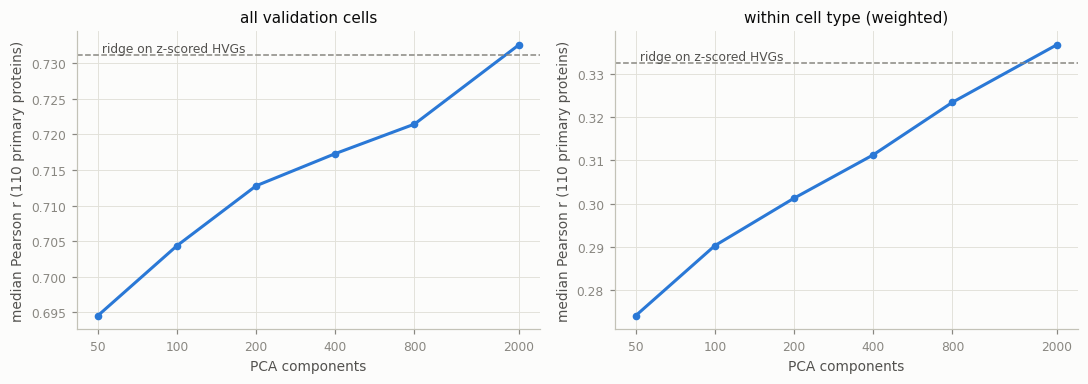

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m, title in zip(axes, ["pearson_all", "within_w"], ["all validation cells", "within cell type (weighted)"]):
    ax.plot(curve["n_pcs"], curve[m], color=P.BLUE, lw=2, marker="o", ms=4, label="ridge on PCA")
    ax.axhline(e_h[m].median(), color=P.MUTED, ls="--", lw=1)
    ax.text(curve["n_pcs"].iloc[0], e_h[m].median(), " ridge on z-scored HVGs", va="bottom", fontsize=8, color=P.INK_2)
    ax.set_xscale("log"); ax.set_xticks(curve["n_pcs"], [str(int(n)) for n in curve["n_pcs"]])
    ax.minorticks_off()
    ax.set_xlabel("PCA components"); ax.set_ylabel("median Pearson r (110 primary proteins)")
    ax.set_title(title)
fig.tight_layout()
fig.savefig(OUT_FIG / "phase3b_pcs_curve.png")
rel = (curve["within_w"].iloc[0] / curve["within_w"].iloc[-1], curve["pearson_all"].iloc[0] / curve["pearson_all"].iloc[-1])
print(f"50 PCs reach {rel[0]:.0%} of the full-rank within-type r and {rel[1]:.0%} of the full-rank overall r")

In [6]:
if SUBSET is None:
    ts_table.to_csv(RESULTS_DIR / "phase3b_within_type_sample.csv")
    curve.to_csv(RESULTS_DIR / "phase3b_pcs_curve.csv", index=False)
import resource, platform
peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
print(f"peak memory: {(peak / 1e9 if platform.system() == 'Darwin' else peak * 1024 / 1e9):.2f} GB")

peak memory: 4.00 GB


## Findings (validation only)

Check: notebook 03's validation predictions are reproduced (max |diff| 2.4e-7).

**1. Most of ridge's within-type correlation disappears once the sample is also held fixed.**

| Model (median over 110 primary proteins) | within type | within type x sample | change |
|---|---|---|---|
| own gene, Phase 2 correlation (all cells; 42 / 296 groups) | 0.072 | 0.062 | -0.01 |
| own gene, validation (34 / 72 groups) | 0.080 | 0.061 | -0.02 |
| ridge on PCA (full rank), validation | 0.337 | 0.104 | **-0.23** |
| ridge on z-scored HVGs, validation | 0.333 | 0.101 | **-0.23** |

* For the own gene, holding the sample fixed changes little. For ridge, about two thirds of the
  within-type correlation is between-sample variation inside a cell type.
* Ridge still beats the own gene within type x sample (0.10 vs 0.06), but by much less than within
  type (+0.04 instead of +0.26).
* This fits the hypothesis that ridge uses sample/site signatures in RNA to predict sample-level
  protein shifts (e.g. the site-dependent background). It may also include real donor differences,
  which this design cannot separate from site, except for donor1. **Not tested which of the two.**
* Caveat: only 72 type x sample groups reach 50 validation cells, so the two columns cover partly
  different cells (the type x sample column is dominated by large types and samples).

**2. Within-type r by number of PCA components.** Ridge with 50 PCs reaches 81% of the full-rank
within-type r (0.27 vs 0.34), but 95% of the full-rank overall r (0.70 vs 0.73). Truncating with PCA
therefore costs relatively more within-type information than overall information, which supports the
hypothesis. Whether the extra within-type signal in the low-variance components is cell-level biology
or sample signature was not tested here.

Peak memory 4.0 GB.